# Gradient Inversion Pipeline Example

## Setup

In [1]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 43.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [2]:
!git clone https://github.com/kbouros/subspace-gradient-inversion.git

Cloning into 'subspace-gradient-inversion'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 27 (delta 5), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 53.75 KiB | 138.00 KiB/s, done.
Resolving deltas: 100% (5/5), done.


In [3]:
import sys

sys.path.append('/content/subspace-gradient-inversion/src')
%cd /content/subspace-gradient-inversion/
!pip install -q -r requirements.txt

/content/subspace-gradient-inversion


In [4]:
# Download tiny-imagenet
import os
import shutil

!wget http://cs231n.stanford.edu/tiny-imagenet-200.zip
!unzip -q -o tiny-imagenet-200.zip -d /content/subspace-gradient-inversion/datasets

# Fix validation folder of tiny-imagenet
val_dir = "/content/subspace-gradient-inversion/datasets/tiny-imagenet-200/val"
img_dir = os.path.join(val_dir, "images")
anno_file = os.path.join(val_dir, "val_annotations.txt")

# Read annotations
with open(anno_file, "r") as f:
    for line in f:
        parts = line.strip().split()
        img_name, class_id = parts[0], parts[1]

        class_folder = os.path.join(val_dir, class_id)
        os.makedirs(class_folder, exist_ok=True)

        src = os.path.join(img_dir, img_name)
        dst = os.path.join(class_folder, img_name)

        if os.path.exists(src):
            shutil.move(src, dst)

shutil.rmtree(img_dir)

--2026-11-09 20:36:10--  http://cs231n.stanford.edu/tiny-imagenet-200.zip
Resolving cs231n.stanford.edu (cs231n.stanford.edu)... 171.64.64.21
Connecting to cs231n.stanford.edu (cs231n.stanford.edu)|171.64.64.21|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://cs231n.stanford.edu/tiny-imagenet-200.zip [following]
--2026-11-09 20:36:10--  https://cs231n.stanford.edu/tiny-imagenet-200.zip
Connecting to cs231n.stanford.edu (cs231n.stanford.edu)|171.64.64.21|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 248100043 (237M) [application/zip]
Saving to: ‘tiny-imagenet-200.zip’

tiny-imagenet-200.z 100%[===================>] 236.61M  8.32MB/s    in 48s     

2026-11-09 20:36:59 (4.95 MB/s) - ‘tiny-imagenet-200.zip’ saved [248100043/248100043]



In [13]:
# Mount drive for ImageNet if needed
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [14]:
# Copy needed files
!mkdir -p /content/subspace-gradient-inversion/datasets/imagenet

!cp /content/drive/MyDrive/imagenet/ILSVRC2012_img_val.tar \
   /content/subspace-gradient-inversion/datasets/imagenet/

!cp /content/drive/MyDrive/imagenet/ILSVRC2012_devkit_t12.tar.gz \
   /content/subspace-gradient-inversion/datasets/imagenet/

In [15]:
# Prepare validation folder
import torchvision

torchvision.datasets.ImageNet(root="/content/subspace-gradient-inversion/datasets/imagenet", split="val")
print("Prepared ImageNet validation set.")

Prepared ImageNet validation set.


## Attack Parameters


In [10]:
# Example options for Imagenet
model = "vgg16"
h_dim = "512" # not meaningful. Only initialized since in most cells it is passed as an argument.
act = "relu" # not meaningful. Only initialized since in most cells it is passed as an argument.
ds = "imagenet"
n_batch = 5
defense = "nodef"
C = 1.0
sigma = 0.0

In [ ]:
# Example options for TinyImagenet
model = "fc3"
h_dim = "512"
act = "leaky_relu"
ds = "tiny_imagenet"
n_batch = 5
defense = "nodef"
C = 1.0
sigma = 0.0

In [5]:
# Example options for CIFAR10.
model = "fc3"
h_dim = "512"
act = "relu"
ds = "cifar10"
n_batch = 5
defense = "nodef"
C = 1.0
sigma = 0.0

## Train and Collect Gradients

In [6]:
# Train CIFAR10 or TinyImagenet model
!python src/train.py --ds={ds} --model={model} --h_dim={h_dim} --act={act} --epochs=20 --batch_size=128 --dry_run


Training fc3 model on cifar10 dataset for 20 epochs
100% 170M/170M [06:04<00:00, 468kB/s]


wandb: Tracking run with wandb version 0.28.1
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /content/subspace-gradient-inversion/wandb/offline-run-20261109_204329-175772h5
wandb: View this run in the terminal with `wandb leet`


Epoch: 1 train_loss: 1.800 test_loss: 1.708 train_acc: 34.91% test_acc: 38.55% time: 11.4
Epoch: 2 train_loss: 1.646 test_loss: 1.645 train_acc: 40.77% test_acc: 40.92% time: 10.4
Epoch: 3 train_loss: 1.589 test_loss: 1.593 train_acc: 42.76% test_acc: 43.32% time: 10.4
Epoch: 4 train_loss: 1.559 test_loss: 1.558 train_acc: 43.87% test_acc: 43.48% time: 10.3
Epoch: 5 train_loss: 1.530 test_loss: 1.560 train_acc: 45.05% test_acc: 44.35% time: 10.5
Epoch: 6 train_loss: 1.511 test_loss: 1.598 train_acc: 45.73% test_acc: 43.47% time: 10.3
Epoch: 7 train_loss: 

In [7]:
!python src/collect_grads.py \
  --ds={ds} \
  --model={model} \
  --h_dim={h_dim} \
  --act={act} \
  --defense={defense} \
  --C={C} \
  --sigma={sigma} \
  --n_batch={n_batch}


Loading model from ./exp/cifar10/fc3/relu/model.pt



Done!
Data saved in ./exp/cifar10/fc3/relu/grads/nodef/8.pickle




Done!
Data saved in ./exp/cifar10/fc3/relu/grads/nodef/16.pickle




Done!
Data saved in ./exp/cifar10/fc3/relu/grads/nodef/32.pickle




Done!
Data saved in ./exp/cifar10/fc3/relu/grads/nodef/64.pickle




Done!
Data saved in ./exp/cifar10/fc3/relu/grads/nodef/128.pickle




Done!
Data saved in ./exp/cifar10/fc3/relu/grads/nodef/256.pickle


Runtime: 4.07 s


## Run Tests

In [8]:
# Hard Affine for CIFAR10 with B=16 (no defense)
!python src/attack.py \
  --n_log=5000 \
  --model={model} \
  --act={act} \
  --h_dim={h_dim} \
  --ds={ds} \
  --defense={defense} \
  --C={C} \
  --sigma={sigma} \
  --attack=gm \
  --batch_size=16 \
  --lr=0.05 \
  --subspace_type=affine \
  --hard_sub \
  --sub_intermediate=1e-4 \
  --tv=1e-4 \
  --n_batch={n_batch} \
  --n_iter=25000 \
  --n_restarts=2 \
  --dry_run \
  --fresh_start


Loading model from ./exp/cifar10/fc3/relu/model.pt


wandb: Tracking run with wandb version 0.28.1
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /content/subspace-gradient-inversion/wandb/offline-run-20261109_204935-5f24hcoa
wandb: View this run in the terminal with `wandb leet`
wandb: WARNING The get_url method is deprecated and will be removed in a future release. Please use `run.url` instead.
wandb: WARNING URL not available in offline run

Wandb: None

exp_path: ./exp/cifar10/fc3/relu/attack/gm_hard_aff/nodef/no_labels/decor_0_tv_0.0001_nv_0_l1_0_aff_inp_0_aff_intermediate_0.0001

Reading gradient data from ./exp/cifar10/fc3/relu/grads/nodef/16.pickle

===Starting Hard Affine Gradient Matching Attack on batch: 0 with batch_size: 16, batch_size_attack: 16 and n_iter=25000===

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/

In [9]:
# Soft Linear for CIFAR10 with B=16 (no defense)
!python src/attack.py \
  --n_log=5000 \
  --model={model} \
  --act={act} \
  --h_dim={h_dim} \
  --ds={ds} \
  --defense={defense} \
  --C={C} \
  --sigma={sigma} \
  --attack=gm \
  --batch_size=16 \
  --lr=0.05 \
  --subspace_type=linear \
  --sub_input=1e-4 \
  --sub_intermediate=1e-4 \
  --tv=1e-4 \
  --n_batch={n_batch} \
  --n_iter=25000 \
  --n_restarts=2 \
  --dry_run \
  --fresh_start


Loading model from ./exp/cifar10/fc3/relu/model.pt


wandb: Tracking run with wandb version 0.28.1
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /content/subspace-gradient-inversion/wandb/offline-run-20261109_211959-k2ojotdc
wandb: View this run in the terminal with `wandb leet`
wandb: WARNING The get_url method is deprecated and will be removed in a future release. Please use `run.url` instead.
wandb: WARNING URL not available in offline run

Wandb: None

exp_path: ./exp/cifar10/fc3/relu/attack/gm_soft_lin/nodef/no_labels/decor_0_tv_0.0001_nv_0_l1_0_lin_inp_0.0001_lin_intermediate_0.0001

Reading gradient data from ./exp/cifar10/fc3/relu/grads/nodef/16.pickle

===Starting Soft Linear Gradient Matching Attack on batch: 0 with batch_size: 16, batch_size_attack: 16 and n_iter=25000===

batch: 0  restart: 0  iter: 0  loss: 1.285  loss_cd: 0.971  loss_tv: 2.249  loss_decor:

In [10]:
# IG for CIFAR10 with B=16 (no defense)
!python src/attack.py \
  --n_log=5000 \
  --model={model} \
  --act={act} \
  --h_dim={h_dim} \
  --ds={ds} \
  --defense={defense} \
  --C={C} \
  --sigma={sigma} \
  --attack=gm \
  --batch_size=16 \
  --lr=0.05 \
  --tv=1e-3 \
  --n_batch={n_batch} \
  --n_iter=25000 \
  --n_restarts=2 \
  --dry_run \
  --fresh_start


Loading model from ./exp/cifar10/fc3/relu/model.pt


wandb: Tracking run with wandb version 0.28.1
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /content/subspace-gradient-inversion/wandb/offline-run-20261109_215206-vr6t1utp
wandb: View this run in the terminal with `wandb leet`
wandb: WARNING The get_url method is deprecated and will be removed in a future release. Please use `run.url` instead.
wandb: WARNING URL not available in offline run

Wandb: None

exp_path: ./exp/cifar10/fc3/relu/attack/gm/nodef/no_labels/decor_0_tv_0.001_nv_0_l1_0_aff_inp_0_aff_intermediate_0

Reading gradient data from ./exp/cifar10/fc3/relu/grads/nodef/16.pickle

===Starting Gradient Matching Attack on batch: 0 with batch_size: 16, batch_size_attack: 16 and n_iter=25000===

batch: 0  restart: 0  iter: 0  loss: 0.973  loss_cd: 0.971  loss_tv: 2.249  loss_decor: 0.0  psnr: 9.682  ssim: 0.015  

In [11]:
# CPA for CIFAR10 with B=16 (no defense)
!python src/attack.py \
  --n_log=5000 \
  --model={model} \
  --act={act} \
  --h_dim={h_dim} \
  --ds={ds} \
  --defense={defense} \
  --C={C} \
  --sigma={sigma} \
  --attack=cp \
  --batch_size=16 \
  --lr=0.001 \
  --decor=1.47 \
  --T=12.4 \
  --tv=3.1 \
  --n_batch={n_batch} \
  --n_iter=25000 \
  --dry_run \
  --fresh_start


Loading model from ./exp/cifar10/fc3/relu/model.pt


wandb: Tracking run with wandb version 0.28.1
wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /content/subspace-gradient-inversion/wandb/offline-run-20261109_222135-j1mmibi5
wandb: View this run in the terminal with `wandb leet`
wandb: WARNING The get_url method is deprecated and will be removed in a future release. Please use `run.url` instead.
wandb: WARNING URL not available in offline run

Wandb: None

exp_path: ./exp/cifar10/fc3/relu/attack/cp/nodef/decor_1.47_t_12.4_tv_3.1_nv_0_l1_0_aff_inp_0_aff_intermediate_0

Reading gradient data from ./exp/cifar10/fc3/relu/grads/nodef/16.pickle

===Starting Cocktail Party Attack on batch: 0 with batch_size: 16, batch_size_attack: 16 and n_iter=25000===

batch: 0  iter: 0  loss: 22309.588  loss_ne: -0.14  loss_decor: 15175.032  loss_tv: 0.784  psnr: 13.338  ssim: 0.439  lpips:

## Optional: Contrast Stretching and Show Reconstructions

In [12]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from utils import read_pickle
from log_utils import get_pil_plot

def percentile_stretch(img, low=0.1, high=99.9):
    """
    Stretch a [B, C, H, W] tensor so that the low-th percentile
    over the entire batch becomes 0 and the high-th percentile becomes 1.

    Returns a torch.Tensor with the same shape/device as img.
    """
    flat = img.reshape(-1)

    lo = torch.quantile(flat, low / 100.0)
    hi = torch.quantile(flat, high / 100.0)

    out = (img - lo) / (hi - lo + 1e-8)
    return out.clamp(0, 1)


def get_attack_name_from_path(path):
    """
    Infer the attack name from a path containing an attack directory.
    """
    parts = os.path.normpath(path).split(os.sep)

    try:
        attack_idx = parts.index("attack")
    except ValueError as exc:
        raise ValueError(
            f"Could not infer the attack name from path because it does not "
            f"contain an 'attack' directory: {path}"
        ) from exc

    if attack_idx + 1 >= len(parts):
        raise ValueError(
            f"The path contains an 'attack' directory but no attack name: {path}"
        )

    name = parts[attack_idx + 1]
    # Remove trailing "_gm" if present (in fi cases)
    if name.endswith("_gm"):
        name = name[:-3]

    name = name.replace("_", " ")

    if name == "gm":
        name = "IG"
    elif name.startswith("gm") and len(name) > 3:
        name = name[3:].title()
    elif name.startswith("cp"):
        name = "CPA"

    return name


def compose_rows_with_labels(
    rows,
    labels,
    output_path,
    font_size = 16,
    font_family = "serif",
    font_weight = "bold",
    figure_width = 12,
    label_space = 0.14,
    label_gap = 0.02,
    row_gap = 0.04,
    show=False,
):
    """
    Compose PIL row images into a vertically stacked Matplotlib figure.

    The image rows remain raster images, while labels added by Matplotlib
    remain vector text when the output format is PDF.

    Parameters
    ----------
    rows:
        PIL images representing complete image rows.

    labels:
        One left-side label for each row.

    output_path:
        Destination PDF or PNG path.

    font_size:
        Matplotlib font size for row labels.

    font_family:
        Matplotlib font family.

    font_weight:
        Label font weight.

    figure_width:
        Width of the complete figure in inches.

    label_space:
        Fraction of the figure width reserved for labels on the left.

    label_gap:
        Distance between each label and its image row, expressed in axes coordinates.

    row_gap:
        Vertical spacing between rows. This is passed to Matplotlib as hspace.

    show:
        Whether to show the figure after saving it.
    """
    rows = list(rows)
    labels = [str(label) for label in labels]
    output_path = Path(output_path)

    if not rows:
        raise ValueError("At least one row image is required.")

    if len(rows) != len(labels):
        raise ValueError(
            "Rows and labels must have the same length. "
            f"Received {len(rows)} rows and {len(labels)} labels."
        )

    row_width, row_height = rows[0].size
    number_of_rows = len(rows)

    # Estimate a figure height that preserves the rows' aspect ratio.
    # Only (1 - label_space) of the figure width is used for image rows.
    image_width_inches = figure_width * (1.0 - label_space)
    one_row_height_inches = image_width_inches * row_height / row_width

    # Account approximately for the vertical spacing between rows.
    spacing_multiplier = 1.0 + row_gap * max(number_of_rows - 1, 0)
    figure_height = number_of_rows * one_row_height_inches * spacing_multiplier

    fig, axes_array = plt.subplots(
        nrows=number_of_rows,
        ncols=1,
        figsize=(figure_width, figure_height),
        squeeze=False,
    )
    axes = axes_array[:, 0]
    fig.subplots_adjust(
        left=label_space,
        right=0.995,
        top=0.995,
        bottom=0.005,
        hspace=row_gap,
    )

    for ax, row, label in zip(axes, rows, labels):
        ax.imshow(row)
        ax.set_axis_off()

        # Put the label immediately to the left of the corresponding row.
        # x=0 is the left edge of the image axes. A negative x position
        # moves the label outside the axes into the reserved label area.
        ax.text(
            -label_gap,
            0.5,
            label,
            transform=ax.transAxes,
            horizontalalignment="right",
            verticalalignment="center",
            fontsize=font_size,
            fontfamily=font_family,
            fontweight=font_weight,
            clip_on=False,
        )

    output_path.parent.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        output_path,
        bbox_inches="tight",
        dpi=300,
    )

    if show:
        plt.show()
    else:
        plt.close(fig)


def create_reconstruction_comparisons(
    pkl_paths,
    batch_indices,
    output_dir="/content",
    ds="cifar10",
    max_items=32,
    ax_dim=3,
    algorithm_names=None,
    stretch_algorithms=None,
    output_format="pdf",
    font_size = 20,
    font_family="serif",
    font_weight="bold",
    figure_width=12,
    label_space=0.14,
    label_gap=0.02,
    row_gap=0.04,
    show=False,
):
    """
    Create reconstruction-comparison figures from multiple pickle files.

    Each pickle file corresponds to one reconstruction algorithm and is
    expected to contain:

        data["inp"]  # input/ground-truth batches
        data["rec"]  # reconstructed batches

    Each generated figure has the following structure:

        True
        Algorithm 1
        Algorithm 2
        ...

    get_pil_plot is used to create each complete image row. Matplotlib
    then stacks those PIL row images and adds bold labels on the left.

    Parameters
    ----------
    pkl_paths:
        One pickle path or a sequence of pickle paths. Each path corresponds
        to one reconstruction algorithm.

    batch_indices:
        One batch index, a sequence of batch indices, or None to generate
        a figure for every available batch.

    output_dir:
        Directory in which comparison figures are saved.

    ds:
        Dataset name passed to get_pil_plot.

    max_items:
        Maximum number of samples displayed in each row.

    ax_dim:
        Matplotlib size in inches allocated to each image.

    algorithm_names:
        Optional names for the reconstruction algorithms. The number of names
        must equal the number of pickle paths. When omitted, names are inferred
        from the paths.

    stretch_algorithms:
        Specifies which reconstruction algorithms should have the percentile
        image stretching postprocessing step applied.

        Can be:

        - None:
            Do not apply stretching to any algorithm.

        - Sequence of integer indices:
            For example, [0, 2] applies stretching to algorithms 0 and 2.

    output_format:
        Either "pdf" or "png".

    font_size:
        Font size of the labels on the left.

    font_family:
        Matplotlib font family used for labels.

    font_weight:
        Matplotlib label weight.

    figure_width:
        Width of the complete output figure in inches.

    label_space:
        Fraction of the figure width reserved for labels.

    label_gap:
        Horizontal distance between labels and image rows.

    row_gap:
        Vertical distance between image rows.

    show:
        Whether to show the figures.

    Returns
    -------
        List of paths of the generated comparison figures.
    """
    # Validate input paths
    if isinstance(pkl_paths, (str, Path)):
        paths = [Path(pkl_paths)]
    else:
        paths = [Path(path) for path in pkl_paths]

    if not paths:
        raise ValueError("At least one pickle path is required.")

    for path in paths:
        if not path.is_file():
            raise FileNotFoundError(f"Pickle file not found: {path}")

    number_of_algorithms = len(paths)

    # Determine which algorithm results should be stretched
    if stretch_algorithms is None:
        stretch_indices = set()
    else:
        stretch_indices = {
            int(index)
            for index in stretch_algorithms
        }
        invalid_stretch_indices = [
            index
            for index in stretch_indices
            if index < 0 or index >= number_of_algorithms
        ]
        if invalid_stretch_indices:
            raise IndexError(
                f"Invalid stretch algorithm indices: {invalid_stretch_indices}. "
                f"Valid indices are 0 through {number_of_algorithms - 1}."
            )

    # Determine algorithm labels
    if algorithm_names is None:
        algorithm_names = []
        for i, path in enumerate(paths):
            algorithm_names.append(
                get_attack_name_from_path(path) + ("+" if i in stretch_indices else "")
            )
    else:
        algorithm_names = [str(name) for name in algorithm_names]

        if len(algorithm_names) != number_of_algorithms:
            raise ValueError(
                "algorithm_names must have one entry per pickle path. "
                f"Received {len(algorithm_names)} names for {number_of_algorithms} paths."
            )

    # Validate output format
    output_format = output_format.lower().lstrip(".")
    if output_format not in {"pdf", "png"}:
        raise ValueError("output_format must be either pdf or png.")

    output_directory = Path(output_dir)
    output_directory.mkdir(parents=True, exist_ok=True)

    # Load pickle files
    loaded = []

    for path in paths:
        data = read_pickle(path)

        if not isinstance(data, dict):
            raise TypeError(
                f"Expected a dictionary in {path}, "
                f"but received {type(data).__name__}."
            )

        if "inp" not in data:
            raise KeyError(f"Missing key 'inp' in {path}.")

        if "rec" not in data:
            raise KeyError(f"Missing key 'rec' in {path}.")

        loaded.append((path, data))

    # Use ground truth from the first pickle
    first_input_batches = loaded[0][1]["inp"]
    number_of_batches = len(first_input_batches)
    max_batch_size = len(first_input_batches[0]) # keep track of the max attack batch size

    # Determine how many batches are shared by every reconstruction file and
    # the maximum attack batch size for potential padding.
    for _, data in loaded:
        temp_number_of_batches = len(data["rec"])
        temp_batch_size = len(data["rec"][0])
        if temp_number_of_batches < number_of_batches:
            number_of_batches = temp_number_of_batches

        if temp_batch_size > max_batch_size:
            max_batch_size = temp_batch_size

    # Validate selected batch indices
    if batch_indices is None:
        selected_batch_indices = list(range(number_of_batches))
    elif isinstance(batch_indices, (int, np.integer)):
        selected_batch_indices = [int(batch_indices)]
    else:
        selected_batch_indices = [int(index) for index in batch_indices]

    if not selected_batch_indices:
        raise ValueError("batch_indices must contain at least one batch index.")

    invalid_indices = [
        index
        for index in selected_batch_indices
        if index < 0 or index >= number_of_batches
    ]

    if invalid_indices:
        raise IndexError(
            f"Invalid batch indices: {invalid_indices}. "
            f"Only batches shared by every file can be selected; "
            f"valid indices are 0 through {number_of_batches - 1}."
        )

    generated_figures = []

    # Create figures for the selected batches
    for batch_index in selected_batch_indices:
        row_images = []
        row_titles = []

        # Ground-truth row. Pad with NaN if x_true has less entries than the max attack batch size.
        x_true = torch.as_tensor(first_input_batches[batch_index])
        x_true = torch.cat([
            x_true,
            torch.full(
                (max(0, max_batch_size - x_true.shape[0]), *x_true.shape[1:]),
                float("nan"),
                dtype=x_true.dtype,
                device=x_true.device,
            ),
        ])

        true_row = get_pil_plot(
            x_true,
            ax_dim=ax_dim,
            max_images=max_items,
            ds=ds,
            norm_method="pixel",
        )

        row_images.append(true_row)
        row_titles.append("True")

        # Reconstruction rows
        for algorithm_index, (algorithm_name, (_, data)) in enumerate(
            zip(algorithm_names, loaded)
        ):

            x_rec = torch.as_tensor(data["rec"][batch_index])

            # Apply stretching to selected algorithms.
            if algorithm_index in stretch_indices:
                x_rec = percentile_stretch(x_rec)

            # Pad with NaN if x_rec has less entries than the max attack batch size.
            x_rec = torch.cat([
                x_rec,
                torch.full(
                    (max(0, max_batch_size - x_rec.shape[0]), *x_rec.shape[1:]),
                    float("nan"),
                    dtype=x_rec.dtype,
                    device=x_rec.device,
                ),
            ])

            reconstruction_row = get_pil_plot(
                x_rec,
                ax_dim=ax_dim,
                max_images=max_items,
                ds=ds,
                norm_method="pixel",
            )

            row_images.append(reconstruction_row)
            row_titles.append(str(algorithm_name))

        # Compose and save using Matplotlib
        output_path = (
            output_directory
            / f"reconstruction_batch_{batch_index}.{output_format}"
        )

        compose_rows_with_labels(
            rows=row_images,
            labels=row_titles,
            output_path=output_path,
            font_size=font_size,
            font_family=font_family,
            font_weight=font_weight,
            figure_width=figure_width,
            label_space=label_space,
            label_gap=label_gap,
            row_gap=row_gap,
            show=show,
        )
        generated_figures.append(output_path)

    return generated_figures

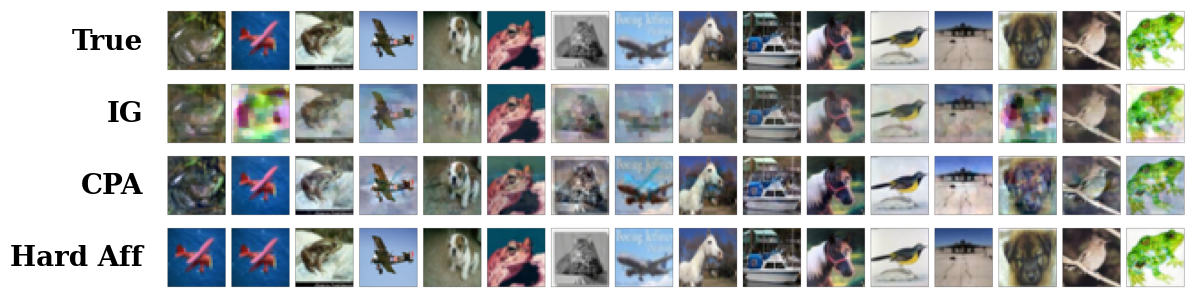

In [13]:
b = 16
ds_attack="cifar10"
act_attack="relu"
figures = create_reconstruction_comparisons(
    pkl_paths=[
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/gm/nodef/no_labels/decor_0_tv_0.001_nv_0_l1_0_aff_inp_0_aff_intermediate_0/{b}_rec.pkl",
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/cp/nodef/decor_1.47_t_12.4_tv_3.1_nv_0_l1_0_aff_inp_0_aff_intermediate_0/{b}_rec.pkl",
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/gm_hard_aff/nodef/no_labels/decor_0_tv_0.0001_nv_0_l1_0_aff_inp_0_aff_intermediate_0.0001/{b}_rec.pkl",
    ],
    batch_indices=[0],
    output_dir="/content",
    ds=ds_attack,
    max_items=16,
    output_format="pdf",
    show=True,
)

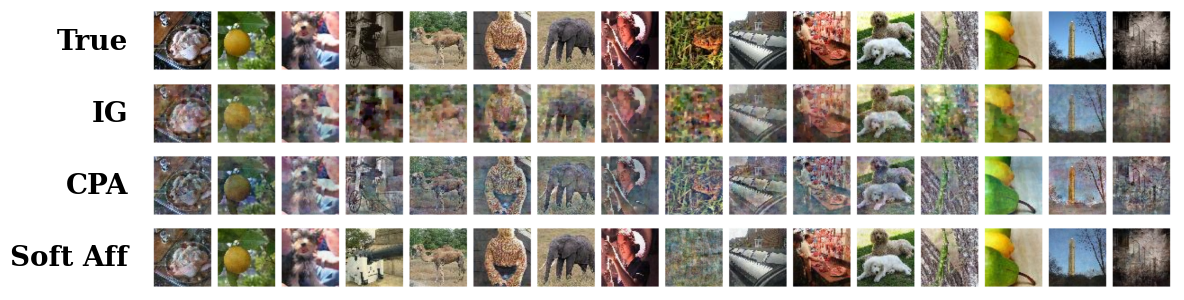

In [ ]:
# Additional results provided the respective pipeline of attacks has been run.
b = 128
ds_attack="tiny_imagenet"
act_attack="leaky_relu"
figures = create_reconstruction_comparisons(
    pkl_paths=[
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/gm/nodef/no_labels/decor_0_tv_0.001_nv_0_l1_0_aff_inp_0_aff_intermediate_0/{b}_rec.pkl",
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/cp/nodef/decor_1.47_t_12.4_tv_3.1_nv_0_l1_0_aff_inp_0_aff_intermediate_0/{b}_rec.pkl",
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/gm_soft_aff/nodef/no_labels/decor_0_tv_0.0001_nv_0_l1_0_aff_inp_0.0001_aff_intermediate_0.0001/{b}_rec.pkl",
    ],
    batch_indices=[0],
    output_dir="/content",
    ds=ds_attack,
    max_items=16,
    output_format="pdf",
    show=True,
)

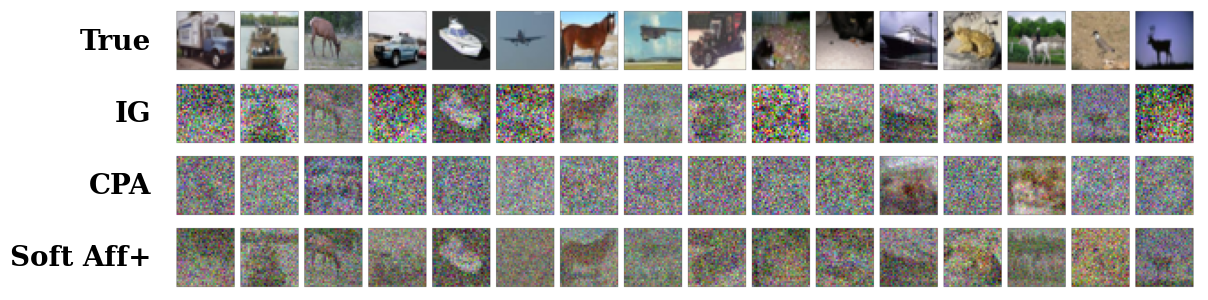

In [ ]:
# Additional results that include constrast stretching provided the respective pipeline of attacks has been run.
sigma = 0.0046
ds_attack="cifar10"
act_attack="relu"
figures = create_reconstruction_comparisons(
    pkl_paths=[
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/gm/dp/no_labels/C_1.0_sigma_{sigma}_decor_0_tv_0.001_nv_0_l1_0_aff_inp_0_aff_intermediate_0/32_rec.pkl",
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/cp/dp/C_1.0_sigma_{sigma}_decor_1.47_t_12.4_tv_3.1_nv_0_l1_0_aff_inp_0_aff_intermediate_0/32_rec.pkl",
        f"./exp/{ds_attack}/fc3/{act_attack}/attack/gm_soft_aff/dp/no_labels/C_1.0_sigma_{sigma}_decor_0_tv_0.0001_nv_0_l1_0_aff_inp_1e-05_aff_intermediate_1e-05/32_rec.pkl",
    ],
    batch_indices=[3],
    stretch_algorithms=[2],
    output_dir="/content",
    ds=ds_attack,
    max_items=16,
    output_format="pdf",
    show=True,
)